# From 2D indentation maps to KAMM-assisted clustering

No MATLAB, MATLAB license, Streamlit or Granta connection is needed. From the repository root, install `python -m pip install -r python/requirements.txt`, then run `python -m jupyterlab python/kamm_clustering.ipynb`.

We compare standardized E-H features with E-H-KAMM using K-means and GMM. Inputs are matching raster maps in **GPa**. KAMM averages `abs(E_i*H_i - E_j*H_j)` on a Manhattan grid shell, **including the zero self-difference** in the denominator. Order 1 has up to four neighbours plus self; order 2 has eight plus self, excluding the inner shell. Missing pixels remain missing, not zero measurements.

This is a reproducible method illustration, not the full article benchmark. Adding KAMM is not guaranteed to improve phase recovery; clusters are not automatically physical phases.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import importlib.metadata as metadata
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from sklearn.metrics import adjusted_rand_score

folder = Path.cwd()
if (folder / 'python' / 'tridimap_ml.py').is_file():
    folder = folder / 'python'
if not (folder / 'tridimap_ml.py').is_file():
    raise RuntimeError('Start Jupyter from the repository root or python folder.')
sys.path.insert(0, str(folder))
from tridimap_ml import cluster_map, kamm_maps

SEED, ORDER, N_PHASES = 42, 1, 3
print({name: metadata.version(name) for name in ('numpy', 'scikit-learn', 'matplotlib')})

{'numpy': '2.4.4', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8'}


In [2]:
rng = np.random.default_rng(SEED)
Y, X = np.indices((48, 48))
x, y = (X - 23.5) / 23.5, (Y - 23.5) / 23.5
ground_truth = np.where(x + 0.15*np.sin(6*y) > 0, 2, 1)
ground_truth[(x-0.1)**2 + (y+0.1)**2 < 0.35**2] = 3

def diffuse(values):
    values = values.astype(float)
    for _ in range(3):
        p = np.pad(values, 1, mode='edge')
        values = (p[1:-1,1:-1] + p[:-2,1:-1] + p[2:,1:-1]
                  + p[1:-1,:-2] + p[1:-1,2:]) / 5
    return values

E = diffuse(np.array([90., 120., 150.])[ground_truth-1]) + rng.normal(0, 6, X.shape)
H = diffuse(np.array([2.8, 3.8, 5.0])[ground_truth-1]) + rng.normal(0, 0.22, X.shape)
E[20:23, 14:17] = np.nan
H[20:23, 14:17] = np.nan
descriptors = kamm_maps(E, H, order=ORDER)
assert np.isnan(descriptors['KAMM'][20:23, 14:17]).all()

C:\Users\dmercier\AppData\Local\Temp\ipykernel_32128\144584477.py:19: UserWarning: Leaving 9 invalid/nonpositive E-H positions unassigned.
  descriptors = kamm_maps(E, H, order=ORDER)


## Use your own 2D maps

Replace the synthetic-data cell with `E = np.genfromtxt('modulus.csv', delimiter=',', ndmin=2)` and the corresponding `H = np.genfromtxt('hardness.csv', delimiter=',', ndmin=2)`. Use numeric, header-free CSV rasters with matching shape, GPa units, rows along Y and columns along X. Keep missing cells as blank/NaN. Set `ground_truth = None` and `Y, X = np.indices(E.shape)` (multiply coordinates by the measured step sizes when exporting).

Do not drop rows/pixels, flatten before KAMM, interpolate across voids, or treat random XY points as raster neighbours. The module also exposes KAEM, KAPM, KAMM_RATIO and signed KAMM_NORMPROD. Select `feature_set='mechanical'` or `'all'` to explore other feature sets. Nonfinite selected feature vectors are excluded, not imputed.

In [3]:
baseline = cluster_map(E, H, n_clusters=N_PHASES, feature_set='eh', order=ORDER, random_state=SEED)
enhanced = cluster_map(E, H, n_clusters=N_PHASES, feature_set='kamm', order=ORDER, random_state=SEED)
gmm = cluster_map(E, H, n_clusters=N_PHASES, feature_set='kamm', method='gmm', order=ORDER, random_state=SEED)
assert baseline.labels.shape == E.shape == enhanced.labels.shape == gmm.labels.shape
assert np.all(enhanced.labels[~enhanced.valid] == 0)
print('Features:', enhanced.feature_names)
print('Assigned pixels:', np.count_nonzero(enhanced.valid), '/', E.size)

C:\github\TriDiMap\python\tridimap_ml.py:119: UserWarning: Leaving 9 invalid/nonpositive E-H positions unassigned.
  descriptors = kamm_maps(e, h, order)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_32128\3871227608.py:1: UserWarning: Excluding 9 invalid measurements or selected feature vectors.
  baseline = cluster_map(E, H, n_clusters=N_PHASES, feature_set='eh', order=ORDER, random_state=SEED)


C:\github\TriDiMap\python\tridimap_ml.py:119: UserWarning: Leaving 9 invalid/nonpositive E-H positions unassigned.
  descriptors = kamm_maps(e, h, order)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_32128\3871227608.py:2: UserWarning: Excluding 9 invalid measurements or selected feature vectors.
  enhanced = cluster_map(E, H, n_clusters=N_PHASES, feature_set='kamm', order=ORDER, random_state=SEED)
C:\github\TriDiMap\python\tridimap_ml.py:119: UserWarning: Leaving 9 invalid/nonpositive E-H positions unassigned.
  descriptors = kamm_maps(e, h, order)
C:\Users\dmercier\AppData\Local\Temp\ipykernel_32128\3871227608.py:3: UserWarning: Excluding 9 invalid measurements or selected feature vectors.
  gmm = cluster_map(E, H, n_clusters=N_PHASES, feature_set='kamm', method='gmm', order=ORDER, random_state=SEED)


Features: ('H', 'E', 'KAMM')
Assigned pixels: 2295 / 2304


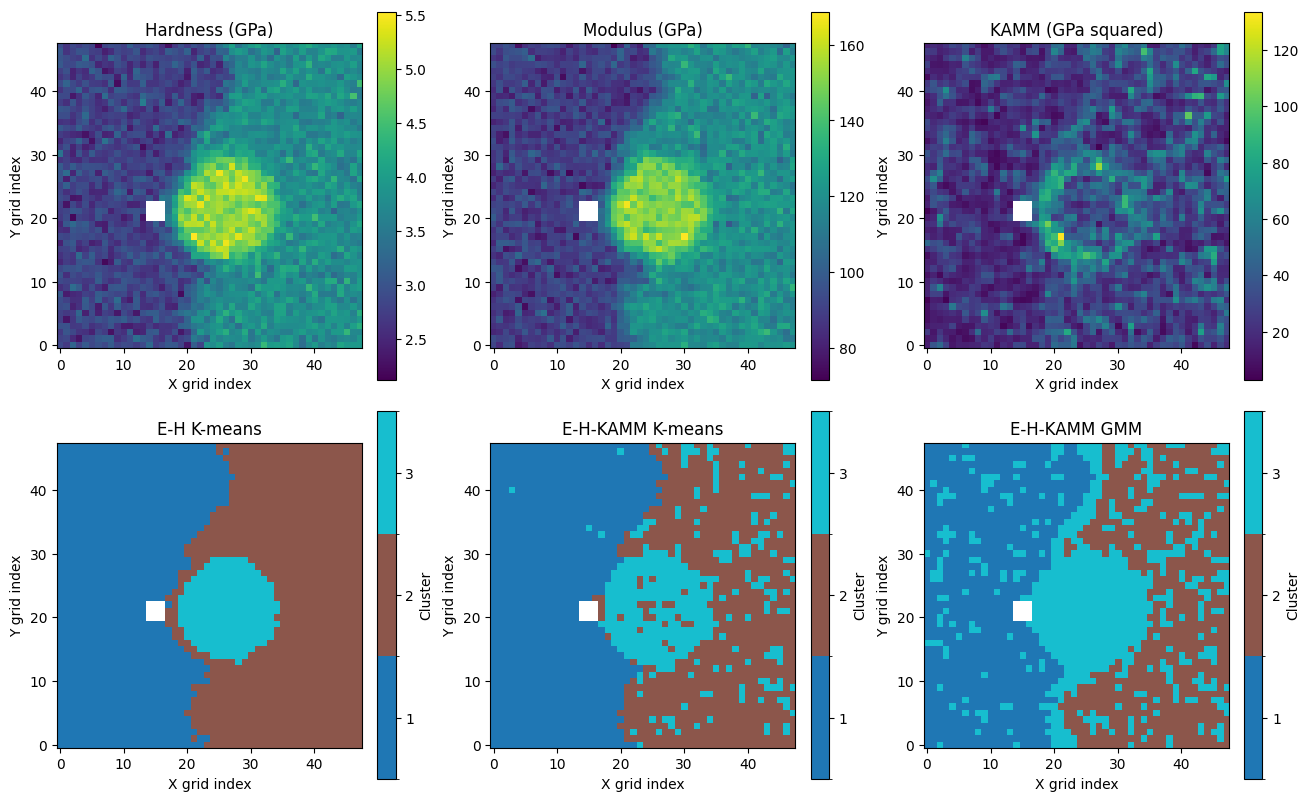

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8), constrained_layout=True)
phase_colors = plt.get_cmap('tab10', N_PHASES)
phase_norm = BoundaryNorm(np.arange(0.5, N_PHASES+1.5), phase_colors.N)
for ax, values, title in zip(axes[0], (H, E, enhanced.descriptors['KAMM']),
                             ('Hardness (GPa)', 'Modulus (GPa)', 'KAMM (GPa squared)')):
    image = ax.imshow(values, origin='lower', cmap='viridis')
    ax.set_title(title)
    fig.colorbar(image, ax=ax)
for ax, result, title in zip(axes[1], (baseline, enhanced, gmm),
                             ('E-H K-means', 'E-H-KAMM K-means', 'E-H-KAMM GMM')):
    image = ax.imshow(np.ma.masked_equal(result.labels, 0), origin='lower',
                      cmap=phase_colors, norm=phase_norm)
    ax.set_title(title)
    fig.colorbar(image, ax=ax, ticks=range(1, N_PHASES+1), label='Cluster')
for ax in axes.ravel():
    ax.set_xlabel('X grid index')
    ax.set_ylabel('Y grid index')
plt.show()

In [5]:
if ground_truth is not None:
    if ground_truth.shape != E.shape:
        raise ValueError('Ground truth must match map shape; set it to None for experimental data.')
    print('Synthetic illustration: adjusted Rand index (higher is better)')
    for name, result in [('E-H K-means', baseline), ('E-H-KAMM K-means', enhanced), ('E-H-KAMM GMM', gmm)]:
        print(f'{name:24s} {adjusted_rand_score(ground_truth[result.valid], result.labels[result.valid]):.3f}')
else:
    print('No known phase labels: validate clusters against independent microstructure evidence.')
print('Results depend on contrast, noise, order, cluster count and model; no universal improvement is claimed.')

Synthetic illustration: adjusted Rand index (higher is better)
E-H K-means              0.929
E-H-KAMM K-means         0.790
E-H-KAMM GMM             0.570
Results depend on contrast, noise, order, cluster count and model; no universal improvement is claimed.


In [6]:
EXPORT = False
if EXPORT:
    table = np.column_stack([X.ravel(), Y.ravel(), E.ravel(), H.ravel(),
                             enhanced.descriptors['KAMM'].ravel(), enhanced.labels.ravel()])
    np.savetxt(folder / 'kamm_clusters.csv', table, delimiter=',', comments='',
               header='X_grid,Y_grid,E_GPa,H_GPa,KAMM_GPa2,Phase')
    print('Exported every position, including NaNs and unassigned phase 0.')
print({'order': ORDER, 'seed': SEED, 'clusters': N_PHASES, 'features': enhanced.feature_names})

{'order': 1, 'seed': 42, 'clusters': 3, 'features': ('H', 'E', 'KAMM')}
